<a href="https://colab.research.google.com/github/pedroabsouza/projeto_desafios_tecnicos_ad/blob/main/desafio_02/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introdução**

Tabela dimensão: **O Cadastro**. Descreve as 'coisas' do tema, onde cada linha é um item único e as colunas são suas características.

Tabela Fato: **O Registro de eventos**. Cada linha é uma ocorrência e traz datas, quantidades e valores medidos. Onde ficam as colunas numéricas que se analisam (Muito mais linhas que as tabelas dimensão)

**Primary Key**: Identificação única, não pode ficar vazia e cada tabela tem a sua

**Foreign Key**: Coluna da tabela fato que guarda a PK de uma linha da dimensão. Liga cada evento ao cadastro.

Obs: Valor ausente nem sempre é erro. Pergunte 'Por que está vazio?'


### Célula 01 - Importar Bibiotecas

In [17]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Célula 02 - Carregando os Dados

In [31]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "atracoes"   # ex.: "livros"
NOME_TABELA_FATO = "ingressos_vendidos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
atracoes -> 10100 linhas
ingressos_vendidos -> 55000 linhas


### Célula 03 - Conhecendo a Tabela Dimensão (Atrações)

In [19]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10100 linhas e 7 colunas (variáveis)


,atracao_id,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,Banda Moura,sertanejo,Festival Illo 2025,2025-01-23,eletronico,20:45
1,2,Coletivo Casa Grande,rap,Festival Nobis 2026,2026-04-20,secundario,13:45
2,3,Banda da Rosa,eletronica,Festival Voluptate 2023,2023-05-23,secundario,12:00
3,4,Banda Farias,rap,Festival Iusto 2026,2026-10-11,principal,16:00
4,5,Rodrigues,reggae,Festival Aperiam 2023,2023-04-06,eletronico,12:30


### Célula 04 - Conhecendo a Tabela Fato (Ingressos_Vendidos)

In [20]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix


### Pergunta a ser respondida:

> "De que maneira o **valor** do ingresso determina a escolha do **canal de venda** (app, site, bilheteria_fisica) e da **forma de pagamento** (pix, cartao_credito), identificando o ponto de corte onde o público passa a preferir o crédito em vez do Pix?"

### Célula 05 · Tipos das colunas

In [21]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos.

df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   venda_id         55000 non-null  int64  
 1   atracao_id       55000 non-null  int64  
 2   tipo_ingresso    55000 non-null  object 
 3   canal_venda      55000 non-null  object 
 4   data_hora_venda  55000 non-null  object 
 5   valor            55000 non-null  float64
 6   forma_pagamento  55000 non-null  object 
dtypes: float64(1), int64(2), object(4)
memory usage: 2.9+ MB


### Célula 06 · Valores ausentes

In [22]:
# 2) Verificar se há valores ausentes. Se sim, somar quantas celulas vazias eu tenho em cada coluna.

print("Valores ausentes por coluna (Tabela Fato - Ingressos_Vendidos):")
print(df_fato.isna().sum())

Valores ausentes por coluna (Tabela Fato - Ingressos_Vendidos):
venda_id           0
atracao_id         0
tipo_ingresso      0
canal_venda        0
data_hora_venda    0
valor              0
forma_pagamento    0
dtype: int64


### Célula 07 · Linhas duplicadas

In [23]:
# 3) Verificar se há linhas duplicadas nas tabelas. Caso sim, procurar onde estão e porque estão duplicadas

print("Linhas duplicadas:", df_fato.duplicated().sum())

Linhas duplicadas: 0


### Célula 08 · Chave estrangeira

In [24]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.

COLUNA_FK = "atracao_id"        # 'atracao_id (coluna da fato que referencia a dimensão, ou seja a PK de dimensao que é FK em fato)
COLUNA_ID = "atracao_id"   # ex.: 'atracao_id (coluna de ID da dimensão)
print("Chaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())

Chaves estrangeiras que batem: True


**Leitura da conferência (Tabela Fato - Ingressos_Vendidos)**

- 55.000 Entradas. Sem linhas duplicadas;
- Chave Estrangeira 'atracao_id' bate com a Chave Primária da Tabela Dimensão (Atrações);
- Sem valores ausentes nestas tabelas, todas células estão preenchidas, conforme verificação.

### Célula 09 - Checar a coluna numérica

In [26]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor" # Coluna VALOR será analisada

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### Célula 10 - Medidas Estatísticas

In [27]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,469.54
Mediana,290.00
Moda,202.98
Desvio padrão,455.12
Variância,207135.74
Mínimo,80.55
Máximo,2975.31
Amplitude,2894.76


Média - mediana: 179.54


## Insights obtidos com as análises de Medida Central (Coluna 'Valor')

- **A **média** de 'valor' é **469.54**. Inidica o valor médio gasto pelos clientes no valor do ingresso, levando em consideração todos os valores, sejam eles baixos ou altos.

- **A **mediana** de 'valor' é 290.00. Indica o valor que está no meio dentre todos os 55.000,00 registros.

- **O **desvio padrão** de 'valor' é 455.12. Mostra o grau de dispersão dos valores em torno da média

#### Conclusões Obtidas:

> Assimetria Positiva (Média > Mediana > Moda): A média é significativamente superior à mediana, que por sua vez é maior que a moda. Isso comprova que a grande maioria das vendas se concentra em ingressos mais baratos, enquanto uma parcela menor de ingressos de alto valor puxa a média para cima.   

> O desvio padrão (R\$ 455,12) é praticamente igual à própria média (R\$ 469,54), o que resulta em um Coeficiente de Variação de aproximadamente 96,9%. Indica alta dispersão e heterogeneidade no conjunto de dados analisado.

> Há também uma Amplitude Elevada: A diferença entre o ingresso mais barato (R\$ 80,55) e o mais caro (R\$ 2.975,31) gera uma amplitude total de R$ 2.894,76, reforçando a existência de faixas de preço muito distantes na mesma base de dados.   

> Para análises de negócio ou relatórios sobre o valor típico do consumidor desse festival, a mediana (R\$ 290,00) é a medida de tendência central mais representativa do comportamento real do público, pois a média (R\$ 469,54) está distorcida pelos valores extremos das categorias superiores.

### Célula 11 - Juntar (JOIN) Tabela Fato com Dimensão

> junta a tabela fato com a dimensão pela chave estrangeira (COLUNA_FK, da fato, com COLUNA_ID, da dimensão) e guarda o resultado em df_completo.

In [28]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro. Se a chave estrangeira bate com a primária, ele une em uma linha só
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim")) # Junta as tabelas priorizando a tabela da esquerda (Nesse caso a Fato), unindo as 2 e tornando uma só
# Observação: Geralmente coloca-se à esquerda a tabela com maior número de Registros

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


In [29]:
df_completo.head() # Mostra a união de tabelas que criamos agora

,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix,Farias,rock,Festival Fuga 2022,2022-11-13,secundario,19:30
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito,As Silveira,eletronica,Festival Neque 2026,2026-04-27,principal,22:00
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix,As Vieira,sertanejo,Festival Fuga 2022,2022-11-12,principal,15:45
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito,Coletivo Costela,sertanejo,Festival Eveniet 2021,2021-04-17,principal,16:00
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix,Santos,funk,Festival Quo 2020,2020-02-13,principal,12:30


### Célula 12 - Comparar grupos por uma coluna da Fato

In [36]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "canal_venda"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

print('\n')

COLUNA_GRUPO = "forma_pagamento"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
canal_venda,,,,
bilheteria_fisica,8234,474.32,289.65,456.82
revenda_parceira,5554,470.17,291.08,447.37
site,22021,469.49,289.26,456.43
app,19191,467.36,290.67,455.13


,count,mean,median,std
forma_pagamento,,,,
cartao_credito,27767,471.45,291.73,455.00
cartao_debito,8228,470.71,291.55,455.38
pix,16252,469.42,287.72,459.52
boleto,2753,447.48,284.45,428.40


**Leitura por (coluna de grupo)**

- (grupo com a maior média e se a mediana confirma)
- (grupo com o maior desvio padrão: valores mais espalhados)
- (se os grupos têm médias parecidas, o que isso diz sobre a categoria)

### Célula 13 · Comparar grupos por uma coluna da dimensão

In [38]:
COLUNA_GRUPO = "edicao_festival"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
edicao_festival,,,,
Festival Sunt 2024,866,509.01,299.77,511.45
Festival Iusto 2026,793,496.13,297.84,477.84
Festival Molestias 2024,795,495.23,300.15,466.82
Festival Excepturi 2019,1167,494.76,297.47,495.03
Festival Quas 2020,1036,489.37,300.83,467.25
Festival Atque 2022,1390,486.45,300.48,467.71
Festival Vel 2021,1023,484.38,289.31,475.98
Festival Quo 2020,2911,482.50,289.44,474.05
Festival Accusantium 2019,765,480.94,292.15,472.20


### Célula 14 · Regra do IQR

In [39]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -347.47 a 1104.52
Outliers: 4653 de 55000 valores
Maiores valores: [2975.31, 2973.81, 2957.95, 2944.94, 2943.81]
Menores valores: [80.55, 81.14, 81.34, 81.77, 81.92]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [40]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,469.54,357.40
Mediana,290.00,273.09
Desvio padrão,455.12,238.74


**Leitura e decisão registrada**

- (quantos valores a regra do IQR marcou, a partir de que valor, e como as medidas mudam sem eles)
- **Decisão:** (manter, tratar ou excluir) e o porquê
- **Valores ausentes:** (o que foi feito com eles e por quê)

### Célula 16 · Assimetria (skew)

In [41]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.36


### Célula 17 · Percentis


In [42]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


### Célula 18 · Quantidade de valores por faixa

In [43]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


# **Recomendação**

> "De que maneira o valor do ingresso determina a escolha do canal de venda (app, site, bilheteria_fisica) e da forma de pagamento (pix, cartao_credito), identificando o ponto de corte onde o público passa a preferir o crédito em vez do Pix?"

**Evidência 1:** (medida + valor + o que significa)
**Evidência 2:** (medida + valor + o que significa)

**Recomendação em uma frase:** (uma frase que alguém de fora da área entenderia)

**Limites da análise:** (os dados são fictícios; o que foi feito com outliers e ausentes, conforme o Passo 8)

### Célula 19 · Histograma

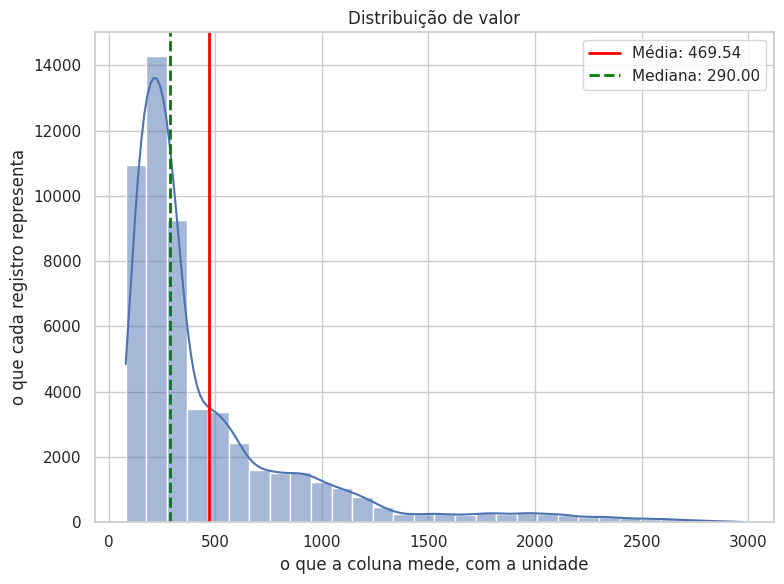

In [44]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("o que cada registro representa")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

### Célula 20 · Boxplot

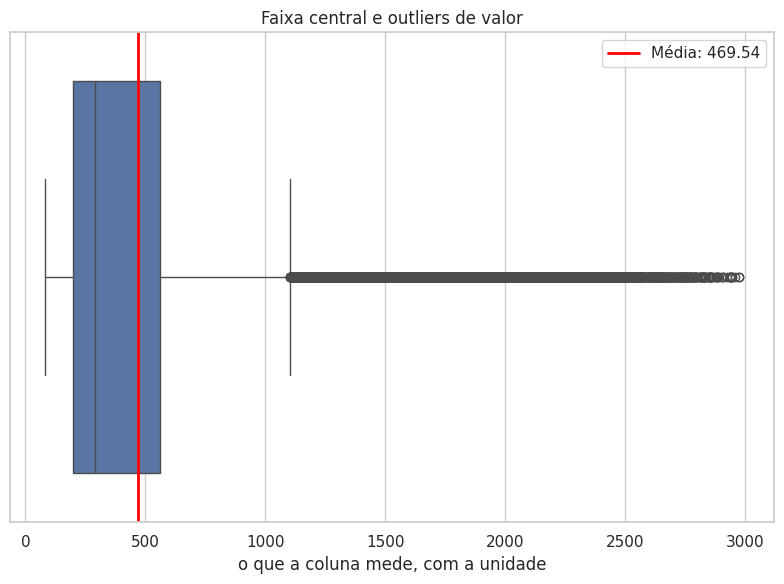

In [45]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()